In [30]:
import numpy as np
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns



### Initialize the environement

In [2]:
# from envs import my_matc_env_rb_strong

# RENDER_MODE = 'sim'

# # Initializing the environment
# flight_route_file = 'routes/matc/auto_airspace_config.json'
# aircraft_config_file = 'routes/matc/aircraft_configurations_auto.json'
# env = my_matc_env_rb_strong.MATCEnv(flight_route_file, aircraft_config_file, render_mode=RENDER_MODE)

In [ ]:
"""You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint,
such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders,   
the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders,     
but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by   
suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.  
Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],   
v: ownship speed(m/s),    
v_min: ownship minimum speed(m/s),   
v_max: ownship maximum speed(m/s),    
d1: the absolute distance between the first front intruder (if any) and ownship(m),    
d2: the absolute distance between the second front intruder (if any) and ownship(m),    
delta_dwpt1: the absolute difference between the distance to the next waypoint between the first front intruder (if any) and ownship(m),    
delta_dwpt2: the absolute difference between the distance to the next waypoint between the second front intruder (if any) and ownship(m),    
delta_v1: signed speed difference between the first front intruder and ownship(m/s),     
delta_v2: signed speed difference between the second front intruder and ownship(m/s),     
same_route1: whether the first front intruder is on the same route as the ownship (1: yes, 0: no),     
same_route2: whether the second front intruder is on the same route as the ownship (1: yes, 0: no).     
If one of the values is None, it means there is no such front intruder.    
Based on the above information, decide the ownship action: Decelerate / Hold / Accelerate. """ 

## Convert the raw ownship-intruder information to the prompts with answers

In [80]:
def get_ownship_prompt(ownship_intruder_info):
    """
    Transform a single ownship-intruder sample into a structured LLM prompt triple.
    Returns (system_prompt, user_prompt, assistant_response)
    """
    def safe_float(val):
        return float('nan') if val is None else float(val)

    ownship_info = ownship_intruder_info['ownship_info']
    raw_first = ownship_intruder_info.get('first_closest_front_intruder_info', []) or {}
    if isinstance(raw_first, list) and len(raw_first) > 0:
        first_intruder_info = raw_first[0]
    elif isinstance(raw_first, dict):
        first_intruder_info = raw_first
    else:
        first_intruder_info = {}
    
    # first_intruder_info = (
    #     ownship_intruder_info['first_closest_front_intruder_info'][0]
    #     if ownship_intruder_info['first_closest_front_intruder_info']
    #     else {}
    # )
    raw_second = ownship_intruder_info.get('second_closest_front_intruder_info', []) or {}
    if isinstance(raw_second, list) and len(raw_second) > 0:
        second_intruder_info = raw_second[0]
    elif isinstance(raw_second, dict):
        second_intruder_info = raw_second
    else:
        second_intruder_info = {}

    # second_intruder_info = (
    #     ownship_intruder_info['second_closest_front_intruder_info'][0]
    #     if ownship_intruder_info['second_closest_front_intruder_info']
    #     else {}
    # )
    ownship_action = ownship_intruder_info['ownship_action']

    # ---- System prompt (fixed global instruction) ----
    system_prompt = """You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, 
    such as merging or intersection points, where other agents (intruders) may also be approaching. Based on the information of the intruders, 
    the ownship should take an action to avoid collisions. The ownship agent only has access to information about the front intruders, 
    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by 
    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.
    Now, given the ownship state: [v, v_min, v_max, delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],
    where:
      v: ownship speed (m/s),
      v_min: ownship minimum speed (m/s),
      v_max: ownship maximum speed (m/s),
      d1: distance between the first front intruder (if any) and the ownship (m),
      d2: distance between the second front intruder (if any) and the ownship (m),
      delta_dwpt1: difference between distances to next waypoint between the first front intruder and the ownship (m),
      delta_dwpt2: difference between distances to next waypoint between the second front intruder and the ownship (m),
      delta_v1: signed speed difference between the first front intruder and ownship (m/s),
      delta_v2: signed speed difference between the second front intruder and ownship (m/s),
      same_route1: 1 if the first intruder is on the same route, 0 otherwise,
      same_route2: 1 if the second intruder is on the same route, 0 otherwise.
    If one of the values is None, it means there is no such front intruder.
    Decide the ownship action: Decelerate / Hold / Accelerate.
    """

    # ---- Build numeric state representation ----
    ownship_spd = ownship_info.get('speed(m/s)', 0.0)
    ownship_min_spd = ownship_info.get('ac_min_spd(m/s)', 0.0)
    ownship_max_spd = ownship_info.get('ac_max_spd(m/s)', 0.0)

    d1 = ownship_info.get('distance_to_intruder1(m)') if ownship_info['num_intruders_ahead'] >= 1 else None
    d2 = ownship_info.get('distance_to_intruder2(m)') if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_dwpt1 = abs(first_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_dwpt2 = abs(second_intruder_info.get('ac_dist_to_nxt_wpt(m)', 0) - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 2 else None

    delta_v1 = first_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 1 else None
    delta_v2 = second_intruder_info.get('speed(m/s)', 0) - ownship_spd if ownship_info['num_intruders_ahead'] >= 2 else None

    same_route1 = ownship_info.get('intruder1_on_same_route') if ownship_info['num_intruders_ahead'] >= 1 else None
    same_route2 = ownship_info.get('intruder2_on_same_route') if ownship_info['num_intruders_ahead'] >= 2 else None

    # ---- User prompt ----
    user_prompt = (
        "Here is the ownship state information:\n"
        f"[v, v_min, v_max, d1, d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2] = "
        f"[{safe_float(ownship_spd):.2f}, {safe_float(ownship_min_spd):.2f}, {safe_float(ownship_max_spd):.2f}, "
        f"{safe_float(d1):.2f}, {safe_float(d2):.2f}, {safe_float(delta_dwpt1):.2f}, {safe_float(delta_dwpt2):.2f}, "
        f"{safe_float(delta_v1):.2f}, {safe_float(delta_v2):.2f}, {safe_float(same_route1):.0f}, {safe_float(same_route2):.0f}]. "
        "Based on the above information, what actions should the ownship take? Skip the explanation."
    )

    # ---- Assistant target ----
    # "The recommended action for the ownship is to 'Accelerate'. \n"
    assistant_response = f"The recommended action for the ownship is to '{ownship_action.capitalize()}'. \n"

    return system_prompt, user_prompt, assistant_response

In [71]:
# def get_ownship_prompt(ownship_intruder_info):
#     """
#     Returns a formatted string prompt for the ownship information.
#     """
#     ownship_info = ownship_intruder_info['ownship_info']
#     first_intruder_info = ownship_intruder_info['first_closest_front_intruder_info']
#     second_intruder_info = ownship_intruder_info['second_closest_front_intruder_info']
#     ownship_action = ownship_intruder_info['ownship_action']

#     system_prompt = """You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, 
#     such as merging or intersections points, where other agents (intruders) are approaching as well. Based on the information of the intruders, 
#     the ownship should take an action to avoid collisions. The ownship agent only has access to the information of the front intruders, 
#     but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by 
#     suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.
#     Now, given the ownship state: [v, v_min, v_max delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],
#     v: ownship speed(m/s), 
#     v_min: ownship minimum speed(m/s), 
#     v_max: ownship maximum speed(m/s),
#     d1: the absolute distance between the first front intruder (if any) and ownship(m), 
#     d2: the absolute distance between the second front intruder (if any) and ownship(m), 
#     delta_dwpt1: the absolute difference between the distance to the next waypoint between the first front intruder (if any) and ownship(m), 
#     delta_dwpt2: the absolute difference between the distance to the next waypoint between the second front intruder (if any) and ownship(m), 
#     delta_v1: signed speed difference between the first front intruder and ownship(m/s), 
#     delta_v2: signed speed difference between the second front intruder and ownship(m/s), 
#     same_route1: whether the first front intruder is on the same route as the ownship (1: yes, 0: no), 
#     same_route2: whether the second front intruder is on the same route as the ownship (1: yes, 0: no). 
#     If one of the values is None, it means there is no such front intruder.
#     Based on the above information, decide the ownship action: Decelerate / Hold / Accelerate.
#     """

#     user_prompt = """Here is the ownship state information:
#     [v, v_min, v_max, d1, d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2] = [{v:.2f}, {v_min:.2f}, {v_max:.2f}, {d1:.2f}, {d2:.2f}, {delta_dwpt1:.2f}, {delta_dwpt2:.2f}, {delta_v1:.2f}, {delta_v2:.2f}, {same_route1:.0f}, {same_route2:.0f}]. 
#     Based on the above information, what actions should the ownship take? Your output must contain exactly one word and no punctuation."""
    
#     ownship_spd = ownship_info['speed(m/s)']
#     ownship_min_spd = ownship_info['ac_min_spd(m/s)']
#     ownship_max_spd = ownship_info['ac_max_spd(m/s)']
#     d1 = ownship_info['distance_to_intruder1(m)'] if ownship_info['num_intruders_ahead'] >= 1 else None
#     d2 = ownship_info['distance_to_intruder2(m)'] if ownship_info['num_intruders_ahead'] >= 2 else None
#     delta_dwpt1 = abs(first_intruder_info['ac_dist_to_nxt_wpt(m)'] - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 1 else None
#     delta_dwpt2 = abs(second_intruder_info['ac_dist_to_nxt_wpt(m)'] - ownship_info['ac_dist_to_nxt_wpt(m)']) if ownship_info['num_intruders_ahead'] >= 2 else None
#     delta_v1 = first_intruder_info['speed(m/s)'] - ownship_spd if ownship_info['num_intruders_ahead'] >= 1 else None
#     delta_v2 = second_intruder_info['speed(m/s)'] - ownship_spd if ownship_info['num_intruders_ahead'] >= 2 else None
#     same_route1 = ownship_info['intruder1_on_same_route'] if ownship_info['num_intruders_ahead'] >= 1 else None
#     same_route2 = ownship_info['intruder2_on_same_route'] if ownship_info['num_intruders_ahead'] >= 2 else None

#     user_prompt = user_prompt.format(
#         v=ownship_spd,
#         v_min=ownship_min_spd,
#         v_max=ownship_max_spd,
#         d1=d1 if d1 is not None else float('nan'),
#         d2=d2 if d2 is not None else float('nan'),
#         delta_dwpt1=delta_dwpt1 if delta_dwpt1 is not None else float('nan'),
#         delta_dwpt2=delta_dwpt2 if delta_dwpt2 is not None else float('nan'),
#         delta_v1=delta_v1 if delta_v1 is not None else float('nan'),
#         delta_v2=delta_v2 if delta_v2 is not None else float('nan'),
#         same_route1=same_route1 if same_route1 is not None else float('nan'),
#         same_route2=same_route2 if same_route2 is not None else float('nan')
#     )

#     prompt_response = f"The recommended action for the ownship is to '{ownship_action}'. \n"
    
#     return system_prompt, user_prompt, prompt_response

In [34]:

# import pandas as pd

# Load the JSONL file
data = []
with open('raw_ownship_intruders_data_Nov10.jsonl', 'r') as file:
    for line in file:
        data.append(json.loads(line.strip()))

print(f"Loaded {len(data)} rows from the file")

Loaded 136267 rows from the file


In [35]:
for row in data[0:2]:
    print(row)

{'ownship_info': {'agent_id': 'AD0001', 'ac_type': 'Google X-Wing', 'ac_lat': 33.0914, 'ac_lon': -96.845907, 'next_wpt_id': 'WP7', 'next_wpt_type': 'Regular', 'ac_dist_to_nxt_wpt(m)': 4778.87, 'speed(m/s)': 13.38, 'ac_min_spd(m/s)': 0.0, 'ac_max_spd(m/s)': 30.87, 'speed_change_per_second(m/s2)': 1.03, 'heading(deg)': 338.82, 'heading_scale': '{North=0, East=90, South=180, West=270}', 'altitude(m)': 1389.36, 'ac_route_id': 'R_4', 'ac_last_action': 'accelerate', 'num_intruders_ahead': 0, 'ac_desired_spd(m/s)': 23.15, 'intruder1_on_same_route': None, 'intruder2_on_same_route': None, 'distance_to_intruder1(m)': None, 'distance_to_intruder2(m)': None, 'time_to_collision_with_inruder1(s)': None, 'time_to_collision_with_inruder2(s)': None, 'did_ownship_have_NMAC': False}, 'first_closest_front_intruder_info': [], 'second_closest_front_intruder_info': [], 'ownship_action': 'Accelerate'}
{'ownship_info': {'agent_id': 'AA0001', 'ac_type': 'Amazon Prime Air - MK30 Model', 'ac_lat': 33.186893, 'ac_

## Data statistics and filtering

### action statistics

In [36]:
actions = [row['ownship_action'] for row in data]
from collections import Counter
action_counts = Counter(actions)
print("Action counts:", action_counts)

Action counts: Counter({'Hold': 83915, 'Accelerate': 37123, 'Decelerate': 15229})


### no-intruders 

In [37]:
no_intruder_data = [row for row in data if row['ownship_info']['num_intruders_ahead'] == 0]
print(f"Number of no-intruder data points: {len(no_intruder_data)}")
# action statistics for no-intruder data
no_intruder_actions = [row['ownship_action'] for row in no_intruder_data]
no_intruder_action_counts = Counter(no_intruder_actions)
print("No-intruder action counts:", no_intruder_action_counts)

Number of no-intruder data points: 38363
No-intruder action counts: Counter({'Hold': 20971, 'Accelerate': 17298, 'Decelerate': 94})


### Only 1 intruder

In [38]:
only_one_intruder_data = [row for row in data if row['ownship_info']['num_intruders_ahead'] == 1]
print(f"Number of only-one-intruder data points: {len(only_one_intruder_data)}")
# action statistics for only-one-intruder data
only_one_intruder_actions = [row['ownship_action'] for row in only_one_intruder_data]
only_one_intruder_action_counts = Counter(only_one_intruder_actions)
print("Only-one-intruder action counts:", only_one_intruder_action_counts)

Number of only-one-intruder data points: 39249
Only-one-intruder action counts: Counter({'Hold': 27631, 'Accelerate': 6915, 'Decelerate': 4703})


### Exactly 2 intruders

In [39]:
exactly_two_intruder_data = [row for row in data if row['ownship_info']['num_intruders_ahead'] == 2]
print(f"Number of exactly-two-intruder data points: {len(exactly_two_intruder_data)}")
# action statistics for exactly-two-intruder data
exactly_two_intruder_actions = [row['ownship_action'] for row in exactly_two_intruder_data]
exactly_two_intruder_action_counts = Counter(exactly_two_intruder_actions)
print("Exactly-two-intruder action counts:", exactly_two_intruder_action_counts)

Number of exactly-two-intruder data points: 58655
Exactly-two-intruder action counts: Counter({'Hold': 35313, 'Accelerate': 12910, 'Decelerate': 10432})


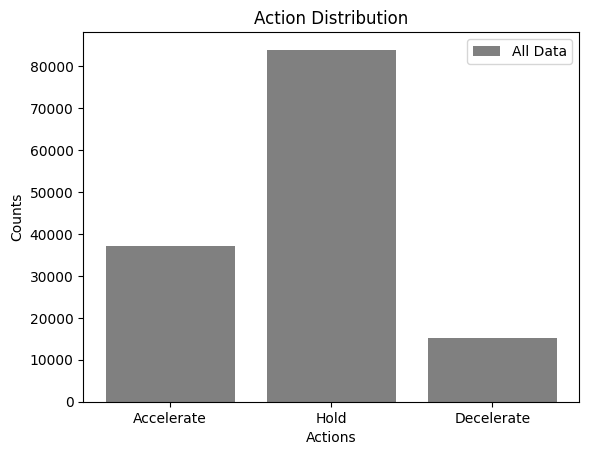

In [41]:
import matplotlib.pyplot as plt

plt.bar(action_counts.keys(), action_counts.values(), color='gray', label='All Data')
# plt.bar(no_intruder_action_counts.keys(), no_intruder_action_counts.values(), color='orange', alpha=0.7, label='No Intruder subset')
# plt.bar(only_one_intruder_action_counts.keys(), only_one_intruder_action_counts.values(), color='blue', alpha=0.7, label='Only One Intruder subset')
# plt.bar(exactly_two_intruder_action_counts.keys(), exactly_two_intruder_action_counts.values(), color='green', alpha=0.7, label='Exactly Two Intruders subset')

plt.title('Action Distribution')
plt.xlabel('Actions')
plt.ylabel('Counts')
plt.legend()
plt.show()

In [42]:
# import pandas as pd

df = pd.json_normalize(data)

In [43]:
# only keep columns related to ownship_info and ownship_action
# example of columns: ownship_info.speed(m/s), ownship_info.ac_min_spd(m/s), ownship_info.ac_max_spd(m/s), ownship_action

matching_columns = [col for col in df.columns if re.match(r'ownship_info\..*|ownship_action', col)]
df_own = df[matching_columns]


In [48]:
# Basic counts
action_counts = Counter(df_own['ownship_action'])
no_intruder_mask = df_own['ownship_info.num_intruders_ahead'] == 0
only_one_intruder_mask = df_own['ownship_info.num_intruders_ahead'] == 1
exactly_two_intruder_mask = df_own['ownship_info.num_intruders_ahead'] == 2

no_intruder_df = df_own[no_intruder_mask]
intruder_df = df_own[~no_intruder_mask]
only_one_intruder_df = df_own[only_one_intruder_mask]
exactly_two_intruder_df = df_own[exactly_two_intruder_mask]
# action_counts

In [45]:
print("\n=== Overall Action Distribution ===")
for k, v in action_counts.items():
    print(f"{k:12s}: {v:>6,d} ({v/len(df_own)*100:.2f}%)")

print(f"\nNo-intruder samples: {len(no_intruder_df):,}")
print("No-intruder Action Counts:", Counter(no_intruder_df['ownship_action']))


=== Overall Action Distribution ===
Accelerate  : 37,123 (27.24%)
Hold        : 83,915 (61.58%)
Decelerate  : 15,229 (11.18%)

No-intruder samples: 38,363
No-intruder Action Counts: Counter({'Hold': 20971, 'Accelerate': 17298, 'Decelerate': 94})


/tmp/ipykernel_507908/4031187757.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='ownship_action', data=df_own, order=['Hold', 'Accelerate', 'Decelerate'], palette='viridis')


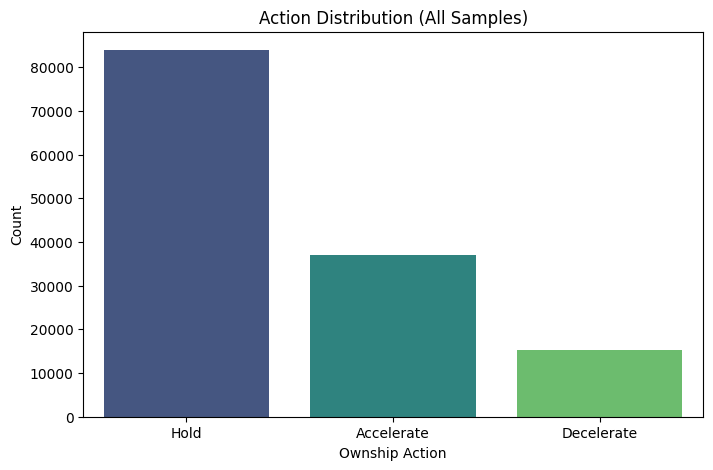

/tmp/ipykernel_507908/4031187757.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='ownship_action', data=no_intruder_df, order=['Hold', 'Accelerate', 'Decelerate'], palette='crest')


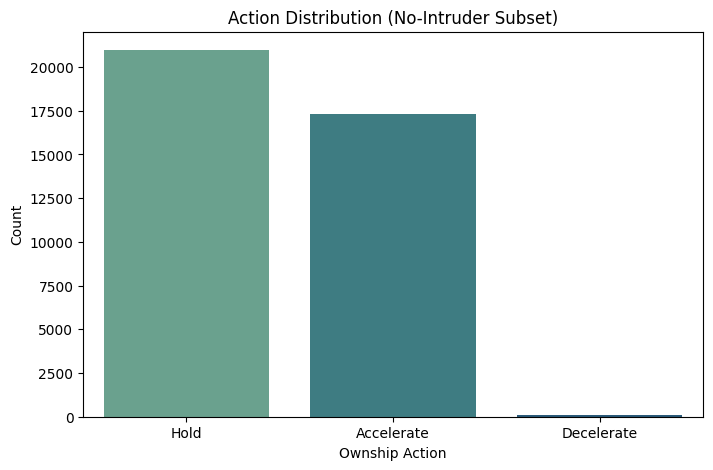

In [46]:
plt.figure(figsize=(8,5))
sns.countplot(x='ownship_action', data=df_own, order=['Hold', 'Accelerate', 'Decelerate'], palette='viridis')
plt.title("Action Distribution (All Samples)")
plt.xlabel("Ownship Action")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,5))
sns.countplot(x='ownship_action', data=no_intruder_df, order=['Hold', 'Accelerate', 'Decelerate'], palette='crest')
plt.title("Action Distribution (No-Intruder Subset)")
plt.xlabel("Ownship Action")
plt.ylabel("Count")
plt.show()

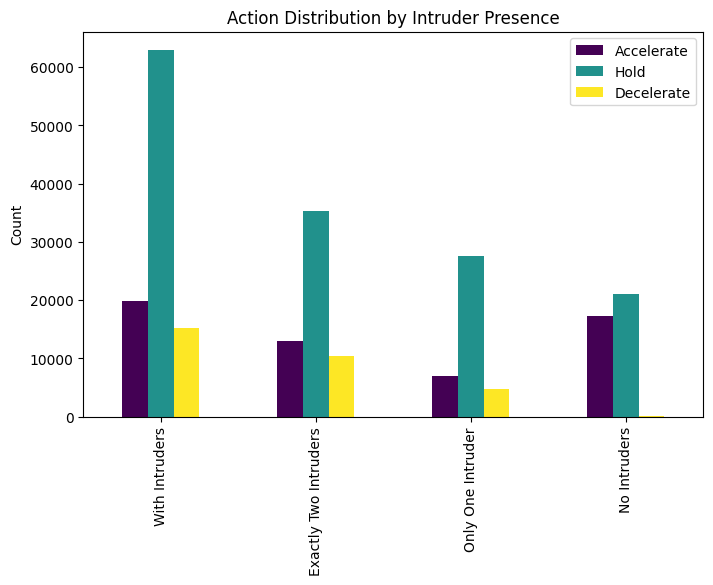

In [50]:
# INTRUDER PRESENCE IMPACT
intruder_summary = pd.DataFrame({
    "With Intruders": Counter(intruder_df['ownship_action']),
    "Exactly Two Intruders": Counter(exactly_two_intruder_df['ownship_action']),
    "Only One Intruder": Counter(only_one_intruder_df['ownship_action']),
    "No Intruders": Counter(no_intruder_df['ownship_action']),    
}).fillna(0).astype(int).T

intruder_summary.plot(kind='bar', figsize=(8,5), colormap='viridis')
plt.title("Action Distribution by Intruder Presence")
plt.ylabel("Count")
plt.show()

### Feature level analysis

In [54]:
num_cols = [
    col for col in df_own.columns 
    if re.match(r'ownship_info\.(speed|distance_to_intruder[12]|ac_dist_to_nxt_wpt|num_intruders_ahead)', col)
]


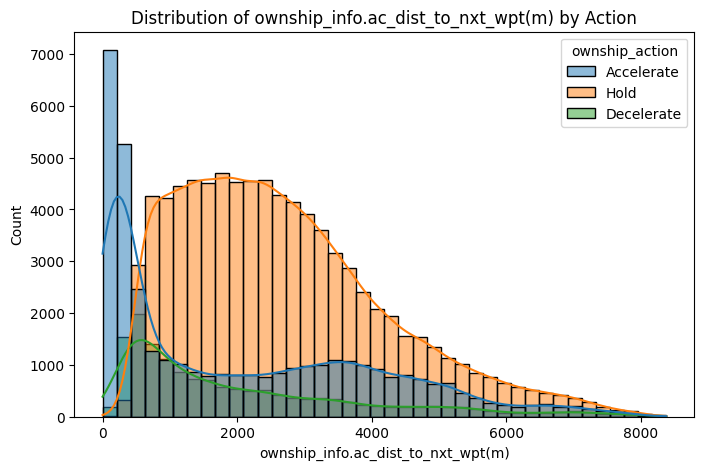

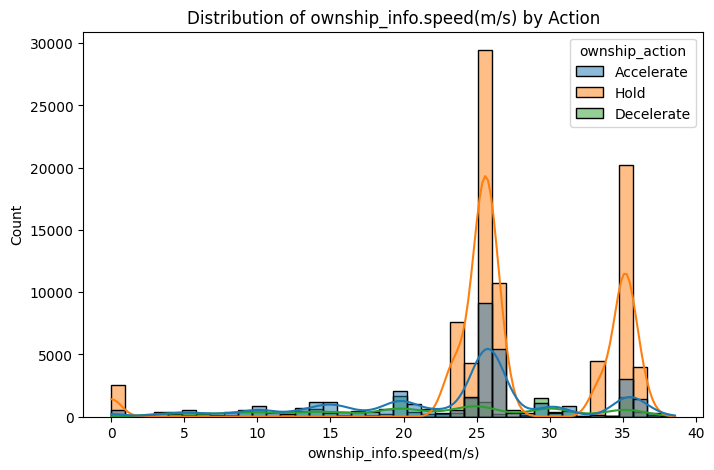

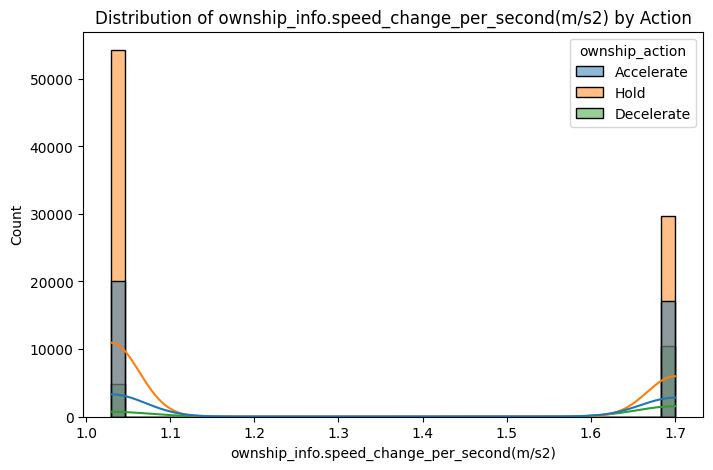

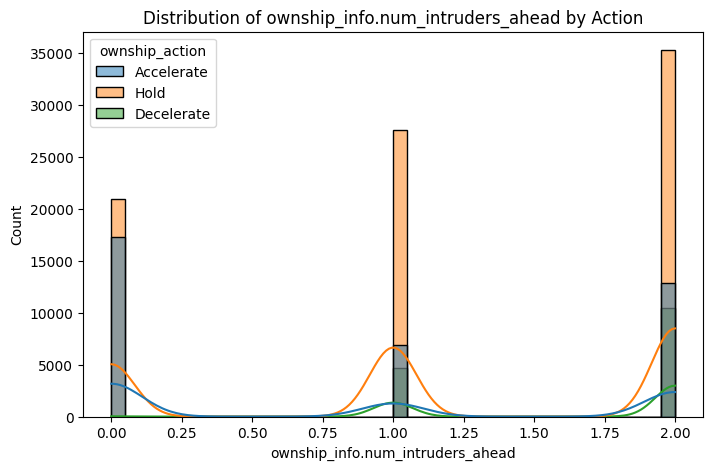

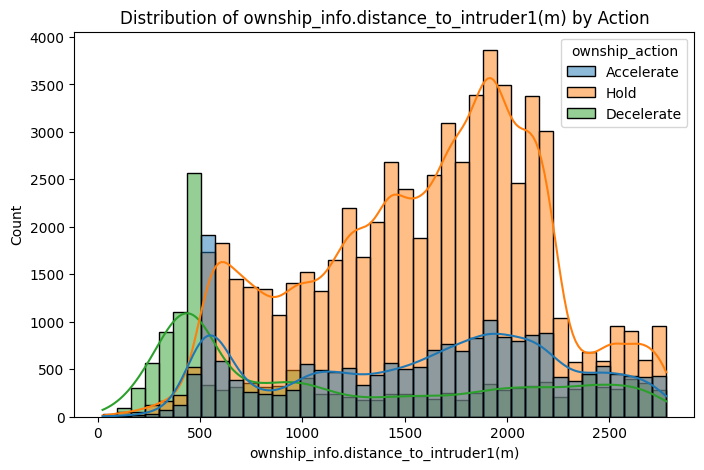

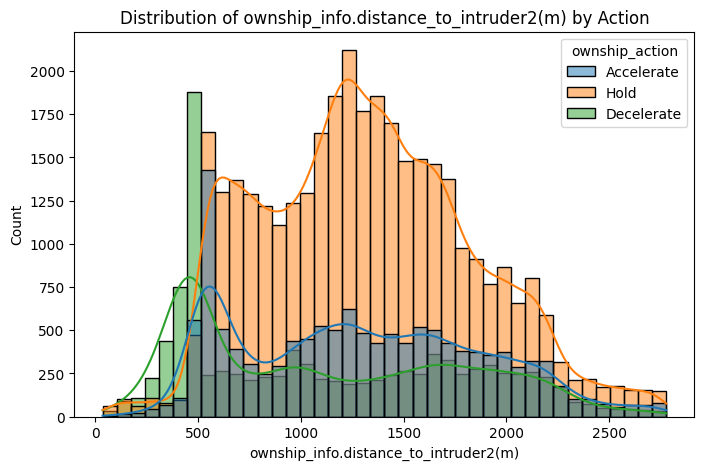

In [55]:
# Plot histograms for each numeric column grouped by action
for col in num_cols:
    if col not in df_own.columns:
        continue
    plt.figure(figsize=(8,5))
    sns.histplot(data=df_own, x=col, hue="ownship_action", bins=40, kde=True)
    plt.title(f"Distribution of {col} by Action")
    plt.xlabel(col)
    plt.show()

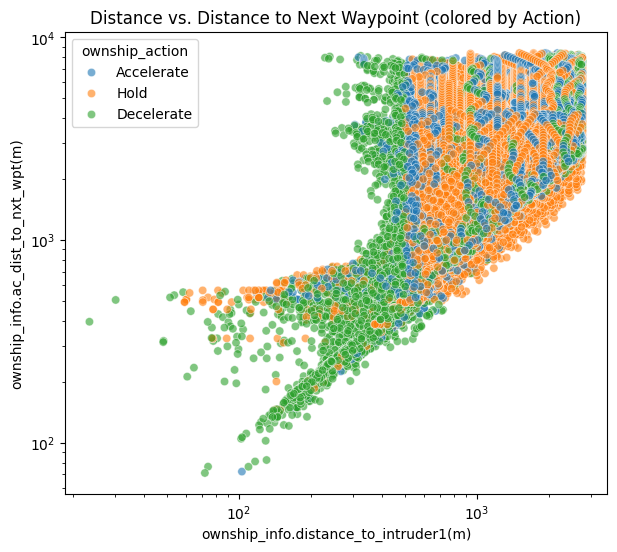

In [60]:
# -------------------------------------------------------------------
#  SCATTERPLOTS: delta_v vs distance (for first intruder)
# -------------------------------------------------------------------
if "ownship_info.distance_to_intruder1(m)" in df_own and "ownship_info.ac_dist_to_nxt_wpt(m)" in df_own:
    plt.figure(figsize=(7,6))
    sns.scatterplot(
        data=intruder_df, 
        x="ownship_info.distance_to_intruder1(m)", 
        y="ownship_info.ac_dist_to_nxt_wpt(m)", 
        hue="ownship_action", alpha=0.6
    )
    plt.title("Distance vs. Distance to Next Waypoint (colored by Action)")
    plt.xscale('log')
    plt.yscale('log')
    plt.show()

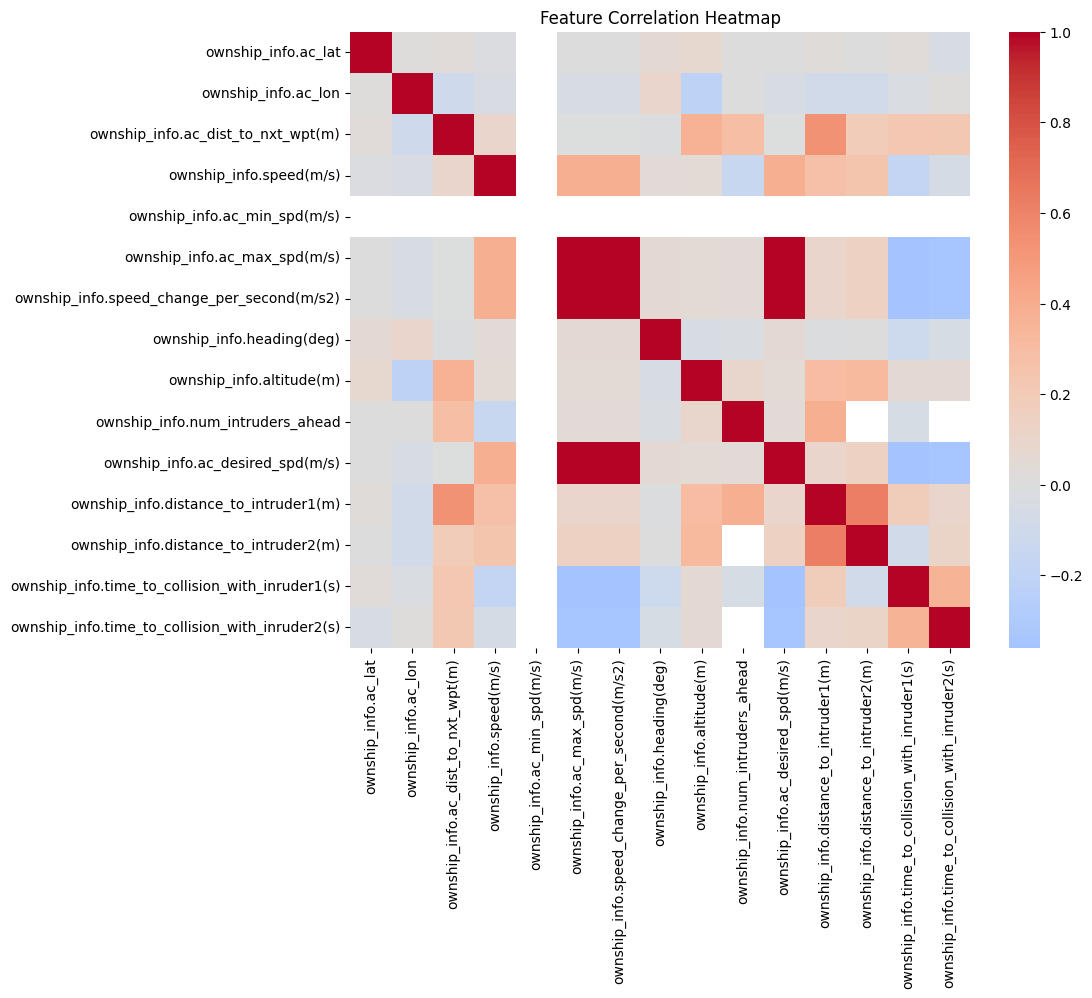

In [61]:
num_features = df_own.select_dtypes(include=[np.number])
corr = num_features.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()


=== Aggregated Metrics by Action ===
               ownship_info.speed(m/s)                    \
                                  mean   std  min    max   
ownship_action                                             
Accelerate                       23.44  8.06  0.0  38.58   
Decelerate                       21.66  9.24  0.0  37.04   
Hold                             27.90  6.77  0.0  37.55   

               ownship_info.ac_dist_to_nxt_wpt(m)                            \
                                             mean      std     min      max   
ownship_action                                                                
Accelerate                                2045.79  1976.67    0.02  8373.07   
Decelerate                                2040.34  1791.20   56.07  8342.08   
Hold                                      2690.40  1547.32  146.11  8379.05   

               ownship_info.num_intruders_ahead                
                                           mean   std min max 

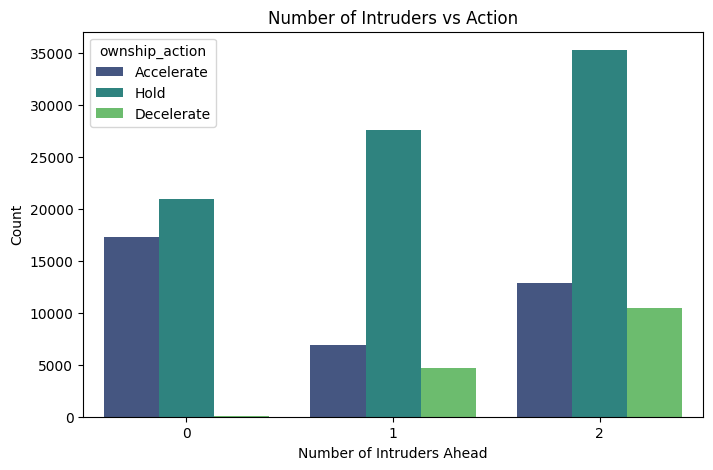

In [64]:
# -------------------------------------------------------------------
# 8. AGGREGATED METRICS
# -------------------------------------------------------------------
agg = df_own.groupby("ownship_action")[
    ["ownship_info.speed(m/s)", "ownship_info.ac_dist_to_nxt_wpt(m)", "ownship_info.num_intruders_ahead"]
].agg(["mean", "std", "min", "max"])

print("\n=== Aggregated Metrics by Action ===")
print(agg.round(2))

# -------------------------------------------------------------------
# 9. INTRUDER COUNT DISTRIBUTION
# -------------------------------------------------------------------
plt.figure(figsize=(8,5))
sns.countplot(x="ownship_info.num_intruders_ahead", hue="ownship_action", data=df_own, palette="viridis")
plt.title("Number of Intruders vs Action")
plt.xlabel("Number of Intruders Ahead")
plt.ylabel("Count")
plt.show()

In [65]:
# -------------------------------------------------------------------
# SUMMARY TEXT
# -------------------------------------------------------------------
print("\n=== SUMMARY INSIGHTS ===")
print(f"Total samples: {len(df_own):,}")
print(f"No-intruder samples: {len(no_intruder_df):,} ({len(no_intruder_df)/len(df_own)*100:.1f}%)")
print("Hold dominates at {:.1f}% overall.".format(action_counts['Hold']/len(df_own)*100))
print("Decelerate appears primarily in intruder-present scenarios (~14% of those cases).")
print("Accelerate mostly occurs when there are no intruders or spacing is large.")
print("→ Recommend class weighting or resampling before training.")


=== SUMMARY INSIGHTS ===
Total samples: 136,267
No-intruder samples: 38,363 (28.2%)
Hold dominates at 61.6% overall.
Decelerate appears primarily in intruder-present scenarios (~14% of those cases).
Accelerate mostly occurs when there are no intruders or spacing is large.
→ Recommend class weighting or resampling before training.


In [68]:
from sklearn.utils.class_weight import compute_class_weight

labels = df_own['ownship_action'].unique()

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=labels,
    y=df_own['ownship_action']
)

class_weight_dict = dict(zip(labels, class_weights))

print("\n=== Computed Class Weights ===")
for label, weight in class_weight_dict.items():
    print(f"{label:12s}: {weight:.3f}")


=== Computed Class Weights ===
Accelerate  : 1.224
Hold        : 0.541
Decelerate  : 2.983


In [82]:
for row in data[:10]:  # Display first 5 rows
    system_prompt, user_prompt, prompt_response = get_ownship_prompt(row)
    print(system_prompt)
    print(user_prompt)
    print(prompt_response)

You are an airspace tactical deconfliction assistant. At each time step, an ownship agent is approaching a bottleneck waypoint, 
    such as merging or intersection points, where other agents (intruders) may also be approaching. Based on the information of the intruders, 
    the ownship should take an action to avoid collisions. The ownship agent only has access to information about the front intruders, 
    but there might be other intruders behind the ownship. Your task is to help the ownship aircraft avoid collisions with front intruder aircraft by 
    suggesting appropriate speed adjustments. The ownship cannot unnecessarily decelerate since it might occlude the airspace for other agents behind it.
    Now, given the ownship state: [v, v_min, v_max, delta_d1, delta_d2, delta_dwpt1, delta_dwpt2, delta_v1, delta_v2, same_route1, same_route2],
    where:
      v: ownship speed (m/s),
      v_min: ownship minimum speed (m/s),
      v_max: ownship maximum speed (m/s),
      d1: distan

In [79]:
len(data)

136267

In [83]:
with open('ownship_prompts_data_Nov10.jsonl', 'w') as outfile:
    for row in data:  
        prompt = {}
        system_prompt, user_prompt, prompt_response = get_ownship_prompt(row)
        prompt['system_prompt'] = system_prompt
        prompt['user_prompt'] = user_prompt
        prompt['prompt_response'] = prompt_response
        outfile.write(json.dumps(prompt) + '\n')